# 03 · CVLI em Alagoas por população (taxas por 100 mil habitantes)

O notebook 02 comparou municípios em **números absolutos**, o que favorece os municípios grandes. Aqui os casos são divididos pela população para responder às perguntas de pesquisa em **taxa por 100 mil habitantes**.

**Fonte da população:** IBGE, via API SIDRA.
- Estimativas anuais (tabela 6579): 2013–2021, 2024 e 2025.
- Censo 2022 (tabela 4709): 2022.
- 2023 não é publicado na tabela de estimativas e foi **interpolado** (média entre 2022 e 2024).

**Atenção à quebra de série.** As estimativas até 2021 partem do Censo 2010. O Censo 2022 contou menos gente em Alagoas (3,13 milhões, contra 3,37 milhões estimados para 2021). Por isso a população cai 7% de 2021 para 2022, sem que isso seja uma perda real. Taxas calculadas antes e depois de 2022 não são perfeitamente comparáveis: o denominador menor de 2022 em diante **infla as taxas recentes** e faz a queda parecer menor. A seção 8 mostra o resultado com a série pré-2022 reescalada ao Censo 2022 para medir esse efeito.

In [1]:
import json, os, re, unicodedata, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
})
COR, COR2, CINZA = "#1f4e79", "#c0504d", "#8a8a8a"
pd.set_option("display.width", 200)

def chave(s):
    """Chave de junção: sem acento, sem apóstrofo/espaço, minúscula."""
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower()
    return re.sub(r"[^a-z0-9]", "", s)

## 1. População por município (IBGE)

In [2]:
ARQ_POP = "../dados_brutos/populacao_municipios_AL.csv"

def sidra(url):
    with urllib.request.urlopen(url, timeout=60) as r:
        dados = json.load(r)[1:]
    t = pd.DataFrame(dados).rename(columns={"D1C": "cod_ibge", "D1N": "municipio", "D3C": "ano", "V": "populacao"})
    return t[["cod_ibge", "municipio", "ano", "populacao"]]

if not os.path.exists(ARQ_POP):
    est = sidra("https://apisidra.ibge.gov.br/values/t/6579/n6/in%20n3%2027/v/9324/p/all?formato=json")
    est["origem"] = "Estimativa IBGE"
    cen = sidra("https://apisidra.ibge.gov.br/values/t/4709/n6/in%20n3%2027/v/93/p/2022?formato=json")
    cen["origem"] = "Censo 2022"
    pop = pd.concat([est, cen])
    pop["ano"] = pop["ano"].astype(int)
    pop["populacao"] = pd.to_numeric(pop["populacao"])
    pop["municipio"] = pop["municipio"].str.replace(" - AL", "", regex=False)
    pop = pop[pop["ano"].between(2013, 2025)].drop_duplicates(["cod_ibge", "ano"])

    # 2023: interpolação linear entre 2022 e 2024
    a22 = pop[pop.ano == 2022].set_index("cod_ibge")
    a24 = pop[pop.ano == 2024].set_index("cod_ibge")
    a23 = ((a22["populacao"] + a24["populacao"]) / 2).round().rename("populacao").reset_index()
    a23["municipio"] = a23["cod_ibge"].map(a22["municipio"]); a23["ano"] = 2023; a23["origem"] = "Interpolado"
    pop = pd.concat([pop, a23]).sort_values(["cod_ibge", "ano"])
    os.makedirs("../dados_brutos", exist_ok=True)
    pop.to_csv(ARQ_POP, index=False, encoding="utf-8-sig")

pop = pd.read_csv(ARQ_POP)
pop["chave"] = pop["municipio"].map(chave)
print(pop.shape, "| municípios:", pop["cod_ibge"].nunique(), "| anos:", pop["ano"].min(), "–", pop["ano"].max())
tot = pop.groupby("ano")["populacao"].sum()
display(tot.to_frame("população de Alagoas").T)

(1326, 6) | municípios: 102 | anos: 2013 – 2025


ano,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
população de Alagoas,3300935.0,3321730.0,3340932.0,3358963.0,3375823.0,3322820.0,3337357.0,3351543.0,3365351.0,3127683.0,3173893.0,3220104.0,3220848.0


## 2. Casos por município e ano, com população

In [3]:
df = pd.read_csv("../dados_brutos/cvli_dados.csv")
df["DATA DO FATO"] = pd.to_datetime(df["DATA DO FATO"], dayfirst=True)
df = df[df["DATA DO FATO"] <= "2025-12-31"].copy()
df["ANO"] = df["DATA DO FATO"].dt.year
df = df[df["ANO"].between(2013, 2025)].copy()
df["chave"] = df["CIDADE DO FATO"].map(chave)
df["HORA"] = pd.to_numeric(df["HORA DO FATO"].str[:2], errors="coerce")

sem_pop = set(df["chave"]) - set(pop["chave"])
print("Municípios da base sem correspondência no IBGE:", sem_pop or "nenhum")

casos = df.groupby(["chave", "ANO"]).size().rename("casos")
grade = pop.set_index(["chave", "ano"])[["municipio", "populacao"]]
grade.index.names = ["chave", "ANO"]
mun = grade.join(casos).fillna({"casos": 0}).reset_index()
mun["casos"] = mun["casos"].astype(int)
mun["taxa"] = mun["casos"] / mun["populacao"] * 1e5
print("Casos na base:", len(df), "| casos após junção:", mun["casos"].sum())

Municípios da base sem correspondência no IBGE: nenhum
Casos na base: 18741 | casos após junção: 18741


## 3. Alagoas: o total caiu mais em taxa ou em número de casos?

Índice com base 2013 = 100. A linha vertical marca a quebra de série da população (Censo 2022).

ANO,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
casos,2247.0,2132.0,1715.0,1767.0,1784.0,1379.0,1096.0,1252.0,1073.0,1137.0,1144.0,1065.0,950.0
populacao,3300935.0,3321730.0,3340932.0,3358963.0,3375823.0,3322820.0,3337357.0,3351543.0,3365351.0,3127683.0,3173893.0,3220104.0,3220848.0
taxa_100mil,68.1,64.2,51.3,52.6,52.8,41.5,32.8,37.4,31.9,36.4,36.0,33.1,29.5


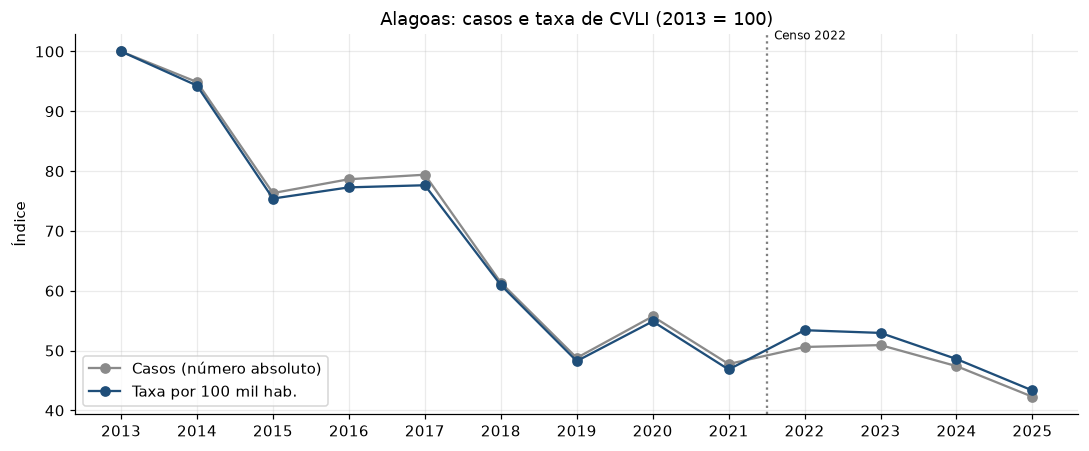

Taxa: 68.1 → 29.5 por 100 mil (-56.7%); casos -57.7%


In [4]:
est = mun.groupby("ANO").agg(casos=("casos", "sum"), populacao=("populacao", "sum"))
est["taxa_100mil"] = est["casos"] / est["populacao"] * 1e5
display(est.round(1).T)

idx = est[["casos", "taxa_100mil"]] / est[["casos", "taxa_100mil"]].iloc[0] * 100
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(idx.index, idx["casos"], marker="o", color=CINZA, label="Casos (número absoluto)")
ax.plot(idx.index, idx["taxa_100mil"], marker="o", color=COR, label="Taxa por 100 mil hab.")
ax.axvline(2021.5, color="k", ls=":", alpha=.5); ax.text(2021.6, 102, "Censo 2022", fontsize=8)
ax.set_title("Alagoas: casos e taxa de CVLI (2013 = 100)"); ax.set_ylabel("Índice"); ax.set_xticks(idx.index)
ax.legend(); plt.tight_layout(); plt.show()
print(f"Taxa: {est.taxa_100mil.iloc[0]:.1f} → {est.taxa_100mil.iloc[-1]:.1f} por 100 mil "
      f"({est.taxa_100mil.iloc[-1] / est.taxa_100mil.iloc[0] - 1:+.1%}); casos {est.casos.iloc[-1] / est.casos.iloc[0] - 1:+.1%}")

## 4. Pergunta 1 · A queda foi homogênea entre os municípios? (taxas)

Compara a taxa agregada de **2013–2015** com a de **2023–2025** (soma de casos dividida pela soma da população de cada triênio). Entram os municípios com pelo menos 150 vítimas no período, os mesmos do notebook 02.

,pop_2025,taxa_13_15,taxa_23_25,var_taxa_%
municipio,,,,
Pilar,36525.0,100.5,27.5,-72.6
Murici,25926.0,126.3,40.0,-68.3
São Sebastião,32707.0,89.2,28.7,-67.8
Marechal Deodoro,62477.0,109.6,35.5,-67.6
Coruripe,51784.0,74.2,24.6,-66.9
São José da Tapera,31569.0,53.0,20.2,-62.0
Santana do Ipanema,47418.0,61.6,24.7,-59.9
Teotônio Vilela,39143.0,66.1,28.2,-57.3
Palmeira dos Índios,73621.0,57.4,24.6,-57.2


Alagoas: 61.2 → 32.9 por 100 mil (-46.3%)
Municípios grandes: 24 com queda de 24; variação mediana -49.0%; amplitude -72.6% a -5.6%


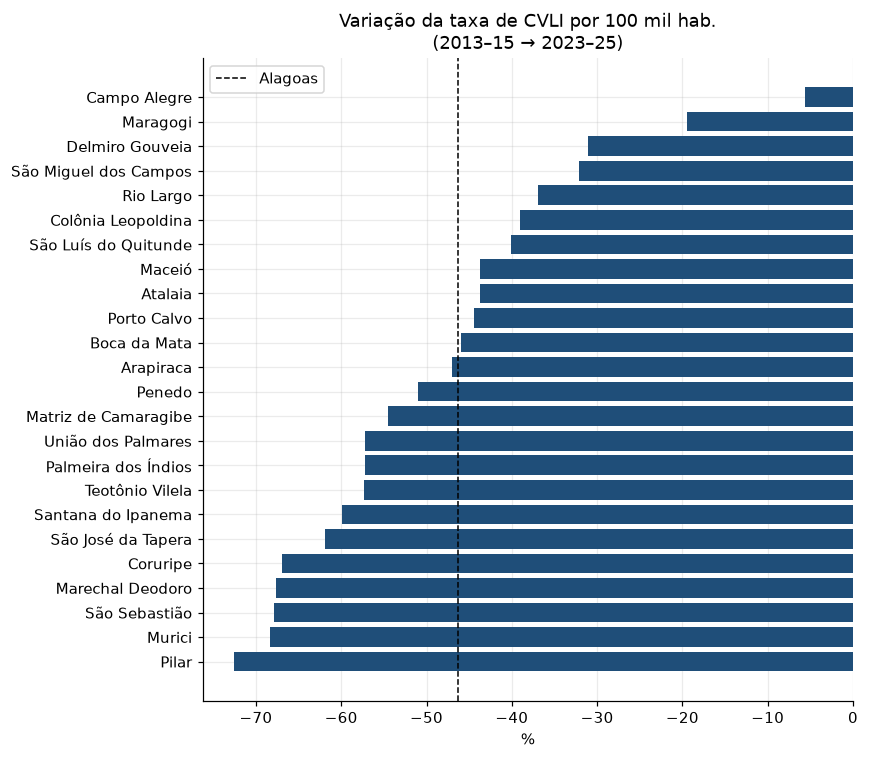

In [5]:
def taxa_periodo(m, ini, fim):
    s = m[m["ANO"].between(ini, fim)].groupby("chave").agg(casos=("casos", "sum"), pop=("populacao", "sum"))
    return s["casos"] / s["pop"] * 1e5

total = mun.groupby("chave")["casos"].sum()
grandes = total[total >= 150].index
nome = mun.drop_duplicates("chave").set_index("chave")["municipio"]

q1 = pd.DataFrame({
    "municipio": nome[grandes],
    "pop_2025": mun[mun.ANO == 2025].set_index("chave")["populacao"][grandes],
    "taxa_13_15": taxa_periodo(mun, 2013, 2015)[grandes],
    "taxa_23_25": taxa_periodo(mun, 2023, 2025)[grandes],
}).set_index("municipio")
q1["var_taxa_%"] = (q1["taxa_23_25"] / q1["taxa_13_15"] - 1) * 100
q1 = q1.sort_values("var_taxa_%")
display(q1.round(1))

est_taxa = [taxa_periodo(mun.assign(chave="AL"), a, b).iloc[0] for a, b in [(2013, 2015), (2023, 2025)]]
print(f"Alagoas: {est_taxa[0]:.1f} → {est_taxa[1]:.1f} por 100 mil ({est_taxa[1]/est_taxa[0]-1:+.1%})")
print(f"Municípios grandes: {(q1['var_taxa_%'] < 0).sum()} com queda de {len(q1)}; "
      f"variação mediana {q1['var_taxa_%'].median():.1f}%; amplitude {q1['var_taxa_%'].min():.1f}% a {q1['var_taxa_%'].max():.1f}%")

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(q1.index, q1["var_taxa_%"], color=np.where(q1["var_taxa_%"] > 0, COR2, COR))
ax.axvline((est_taxa[1] / est_taxa[0] - 1) * 100, color="k", ls="--", lw=1, label="Alagoas")
ax.set_title("Variação da taxa de CVLI por 100 mil hab.\n(2013–15 → 2023–25)"); ax.set_xlabel("%")
ax.legend(); plt.tight_layout(); plt.show()

In [6]:
# A leitura muda quando se passa de números absolutos para taxa?
casos_13_15 = mun[mun.ANO.between(2013, 2015)].groupby("chave")["casos"].sum()
casos_23_25 = mun[mun.ANO.between(2023, 2025)].groupby("chave")["casos"].sum()
comp = pd.DataFrame({"var_casos_%": ((casos_23_25 / casos_13_15 - 1) * 100)[grandes]})
comp.index = nome[grandes].values
comp = comp.join(q1["var_taxa_%"])
display(comp.sort_values("var_taxa_%").round(1))
print("Correlação de Spearman entre variação de casos e de taxa:", round(comp.corr(method="spearman").iloc[0, 1], 2))
print("Diferença mediana (taxa − casos), em p.p.:", round((comp["var_taxa_%"] - comp["var_casos_%"]).median(), 1))

,var_casos_%,var_taxa_%
Pilar,-71.7,-72.6
Murici,-71.0,-68.3
São Sebastião,-69.2,-67.8
Marechal Deodoro,-60.2,-67.6
Coruripe,-69.6,-66.9
São José da Tapera,-62.7,-62.0
Santana do Ipanema,-60.2,-59.9
Teotônio Vilela,-62.1,-57.3
Palmeira dos Índios,-57.5,-57.2
União dos Palmares,-60.6,-57.2


Correlação de Spearman entre variação de casos e de taxa: 0.91
Diferença mediana (taxa − casos), em p.p.: 2.0


## 5. Pergunta 5 · Municípios de maior e menor incidência

Para a taxa de 2023–2025 só entram municípios com **20 mil habitantes ou mais**: em cidade pequena, poucos casos já mudam muito a taxa.

In [7]:
t25 = mun[mun.ANO.between(2023, 2025)].groupby("chave").agg(casos=("casos", "sum"), pop=("populacao", "sum"), pop_media=("populacao", "mean"))
t25["taxa"] = t25["casos"] / t25["pop"] * 1e5
t25["municipio"] = nome
t25["taxa_13_15"] = taxa_periodo(mun, 2013, 2015)
t25 = t25[t25["pop_media"] >= 20000].sort_values("taxa", ascending=False)
print(len(t25), "municípios com 20 mil habitantes ou mais")
cols = ["municipio", "pop_media", "casos", "taxa", "taxa_13_15"]
print("Maior incidência (2023–25):"); display(t25[cols].head(10).round(1))
print("Menor incidência (2023–25):"); display(t25[cols].tail(10).round(1))
print(f"Razão entre a maior e a menor taxa: {t25.taxa.max() / t25.taxa.min():.1f}x | mediana {t25.taxa.median():.1f} | Maceió {t25.loc['maceio', 'taxa']:.1f}")

39 municípios com 20 mil habitantes ou mais
Maior incidência (2023–25):


,municipio,pop_media,casos,taxa,taxa_13_15
chave,,,,,
riolargo,Rio Largo,96924.7,178,61.2,97.0
igaci,Igaci,24373.7,39,53.3,40.9
saomigueldoscampos,São Miguel dos Campos,53153.7,79,49.5,73.0
maragogi,Maragogi,33068.0,47,47.4,58.8
murici,Murici,25806.3,31,40.0,126.3
campoalegre,Campo Alegre,32560.7,38,38.9,41.2
atalaia,Atalaia,38343.7,44,38.3,68.0
maceio,Maceió,988535.3,1130,38.1,67.7
matrizdecamaragibe,Matriz de Camaragibe,24251.7,26,35.7,78.6


Menor incidência (2023–25):


,municipio,pop_media,casos,taxa,taxa_13_15
chave,,,,,
saojosedatapera,São José da Tapera,31402.0,19,20.2,53.0
delmirogouveia,Delmiro Gouveia,52572.7,31,19.7,28.5
olhodaguadasflores,Olho d'Água das Flores,21060.3,11,17.4,46.4
vicosa,Viçosa,24365.0,12,16.4,66.0
traipu,Traipu,24024.7,11,15.3,19.3
limoeirodeanadia,Limoeiro de Anadia,25116.3,7,9.3,38.7
paodeacucar,Pão de Açúcar,24213.0,6,8.3,30.8
junqueiro,Junqueiro,24302.3,6,8.2,57.2
piranhas,Piranhas,22979.0,5,7.3,49.8


Razão entre a maior e a menor taxa: 8.5x | mediana 28.2 | Maceió 38.1


In [8]:
# Perfil dos casos nos municípios de maior e menor incidência (quartis da taxa 2023–25)
t25["grupo"] = pd.qcut(t25["taxa"], 4, labels=["Q1 menor", "Q2", "Q3", "Q4 maior"])
d = df.merge(t25[["grupo"]], left_on="chave", right_index=True)
d["noite"] = d["HORA"].between(18, 23)
d["mulher"] = d["SEXO DA VITIMA"].eq("Feminino")
d["arma_fogo"] = d["INSTRUMENTO UTILIZADO"].astype(str).str.upper().str.startswith("PAF")
perfil = d.groupby("grupo", observed=True).agg(
    municipios=("chave", "nunique"), casos=("chave", "size"),
    pct_noite=("noite", "mean"), pct_mulheres=("mulher", "mean"), pct_arma_fogo=("arma_fogo", "mean"))
perfil[["pct_noite", "pct_mulheres", "pct_arma_fogo"]] *= 100
perfil["taxa_mediana_23_25"] = t25.groupby("grupo", observed=True)["taxa"].median()
display(perfil.round(1))

,municipios,casos,pct_noite,pct_mulheres,pct_arma_fogo,taxa_mediana_23_25
grupo,,,,,,
Q1 menor,10,1069,43.7,6.5,76.0,12.3
Q2,10,2303,41.4,7.1,79.2,24.6
Q3,9,2853,43.2,6.4,76.7,30.8
Q4 maior,10,8898,42.1,6.5,78.0,39.5


## 6. Pergunta 6 · Concentração territorial em termos populacionais

Se a violência estivesse distribuída conforme a população, cada município teria a mesma fatia de casos e de habitantes. A curva abaixo ordena os municípios da maior para a menor taxa e compara a fatia acumulada da população com a dos casos. Quanto mais a curva se afasta da diagonal, maior a concentração.

2013–2015: os municípios com maiores taxas que somam 50% dos casos reúnem 52% da população (índice de concentração 0.17)
2023–2025: os municípios com maiores taxas que somam 50% dos casos reúnem 46% da população (índice de concentração 0.19)


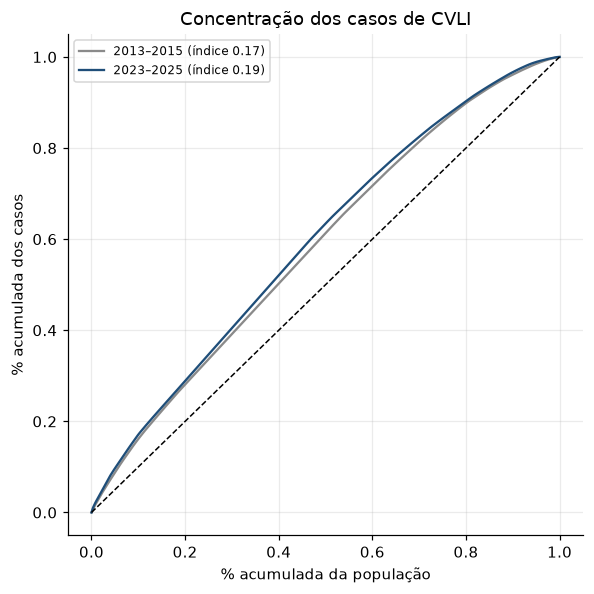

In [9]:
def concentracao(ini, fim):
    s = mun[mun.ANO.between(ini, fim)].groupby("chave").agg(casos=("casos", "sum"), pop=("populacao", "sum"))
    s["taxa"] = s["casos"] / s["pop"]
    s = s.sort_values("taxa", ascending=False)
    x = np.r_[0, s["pop"].cumsum() / s["pop"].sum()]
    y = np.r_[0, s["casos"].cumsum() / s["casos"].sum()]
    return x, y, 2 * (np.trapezoid(y, x) - 0.5)   # área entre a curva e a diagonal, x2

fig, ax = plt.subplots(figsize=(5.5, 5.5))
for (ini, fim), cor in zip([(2013, 2015), (2023, 2025)], [CINZA, COR]):
    x, y, g = concentracao(ini, fim)
    ax.plot(x, y, color=cor, label=f"{ini}–{fim} (índice {g:.2f})")
    meio = np.searchsorted(y, 0.5)
    print(f"{ini}–{fim}: os municípios com maiores taxas que somam 50% dos casos reúnem {x[meio]:.0%} da população (índice de concentração {g:.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("% acumulada da população"); ax.set_ylabel("% acumulada dos casos")
ax.set_title("Concentração dos casos de CVLI"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

ANO,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
grupo,,,,,,,,,,,,,
Arapiraca,65.89,65.41,53.23,61.89,47.83,42.97,36.68,36.47,39.26,30.68,38.88,33.24,25.83
Interior,61.83,61.38,50.76,54.69,50.37,38.99,33.69,37.50,31.63,35.24,32.88,31.23,26.69
Maceió,81.57,69.73,52.08,46.20,59.08,46.33,30.23,37.26,30.73,39.98,41.69,36.70,35.98
Razão Maceió/Interior,1.32,1.14,1.03,0.84,1.17,1.19,0.90,0.99,0.97,1.13,1.27,1.18,1.35


Parcela da população em Maceió (2025): 30.9% | parcela dos casos (2023–25): 35.8%


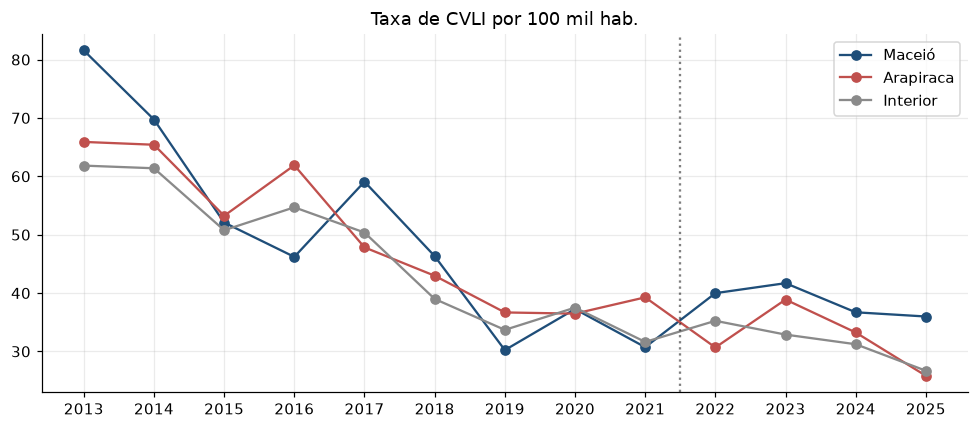

Persistência: correlação de Spearman entre as taxas de 2013–15 e 2023–25 = 0.44 (p = 0.0033, n = 42 municípios)


In [10]:
# Capital, Arapiraca e interior: taxa por grupo e razão capital/interior
mun["grupo"] = np.where(mun["chave"] == "maceio", "Maceió", np.where(mun["chave"] == "arapiraca", "Arapiraca", "Interior"))
g = mun.groupby(["ANO", "grupo"]).agg(casos=("casos", "sum"), pop=("populacao", "sum")).unstack()
taxa_g = g["casos"] / g["pop"] * 1e5
taxa_g["Razão Maceió/Interior"] = taxa_g["Maceió"] / taxa_g["Interior"]
display(taxa_g.round(2).T)
print("Parcela da população em Maceió (2025):", f"{g['pop']['Maceió'].iloc[-1] / g['pop'].iloc[-1].sum():.1%}",
      "| parcela dos casos (2023–25):", f"{g['casos']['Maceió'].iloc[-3:].sum() / g['casos'].iloc[-3:].sum().sum():.1%}")

fig, ax = plt.subplots(figsize=(9, 4))
for c, cor in zip(["Maceió", "Arapiraca", "Interior"], [COR, COR2, CINZA]):
    ax.plot(taxa_g.index, taxa_g[c], marker="o", color=cor, label=c)
ax.axvline(2021.5, color="k", ls=":", alpha=.5)
ax.set_title("Taxa de CVLI por 100 mil hab."); ax.set_xticks(taxa_g.index); ax.legend(); plt.tight_layout(); plt.show()

from scipy.stats import spearmanr
a, b = [mun[mun.ANO.between(i, f)].groupby("chave").agg(c=("casos", "sum"), p=("populacao", "sum")) for i, f in [(2013, 2015), (2023, 2025)]]
r = pd.concat([a["c"] / a["p"], b["c"] / b["p"]], axis=1)[a["p"] / 3 >= 20000]
rho, p = spearmanr(r.iloc[:, 0], r.iloc[:, 1])
print(f"Persistência: correlação de Spearman entre as taxas de 2013–15 e 2023–25 = {rho:.2f} (p = {p:.2g}, n = {len(r)} municípios)")

## 7. Pergunta 2 · Mulheres em taxa por 100 mil habitantes

A população por sexo não está disponível por município e ano nesta fonte. A taxa abaixo usa a **população total** no denominador (mulheres vítimas por 100 mil habitantes). Serve para comparar a tendência com a dos homens, não como taxa por 100 mil mulheres.

ANO,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
mulheres,148.00,133.00,95.00,97.00,115.00,68.00,91.00,101.00,71.00,74.00,80.00,74.00,94.00
feminicidios,0.00,0.00,11.00,37.00,34.00,21.00,43.00,35.00,25.00,31.00,18.00,21.00,30.00
taxa_mulheres,4.48,4.00,2.84,2.89,3.41,2.05,2.73,3.01,2.11,2.37,2.52,2.30,2.92
taxa_homens,63.59,60.18,48.49,49.72,49.44,39.45,30.11,34.34,29.77,33.99,33.52,30.78,26.58
taxa_feminicidios,0.00,0.00,0.33,1.10,1.01,0.63,1.29,1.04,0.74,0.99,0.57,0.65,0.93


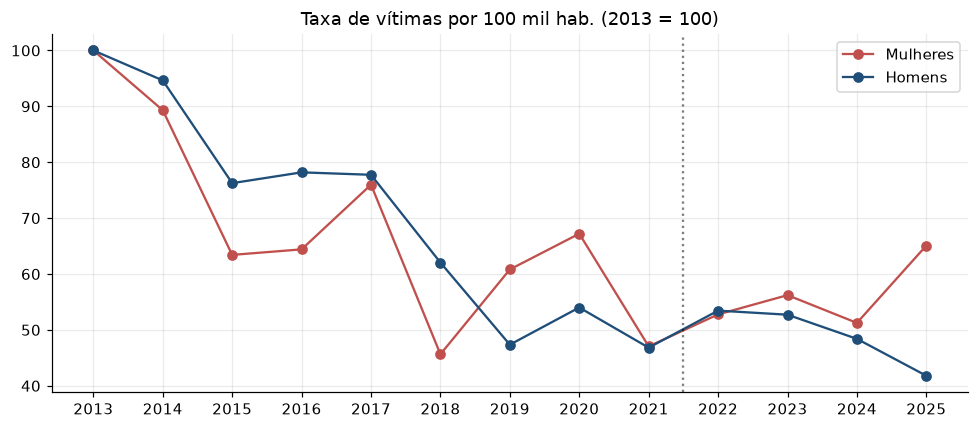

mulheres: 3.77 → 2.58 por 100 mil hab. (-31.7%)
homens: 57.39 → 30.28 por 100 mil hab. (-47.2%)
feminicídios classificados (base 2016–18): 0.91 → 0.72 por 100 mil hab. (-21.5%)
mulheres, mesma base 2016–18: 2.78 → 2.58 (-7.3%) | homens: 46.23 → 30.28 (-34.5%)


In [11]:
f = df.assign(mulher=df["SEXO DA VITIMA"].eq("Feminino"), fem=df["SUBJETIVIDADE COMPLEMENTAR"].eq("Feminicídio"))
sx = f.groupby("ANO").agg(mulheres=("mulher", "sum"), feminicidios=("fem", "sum"), total=("mulher", "size"))
sx["homens"] = sx["total"] - sx["mulheres"]
for c in ["mulheres", "homens", "feminicidios"]:
    sx[f"taxa_{c}"] = sx[c] / est["populacao"] * 1e5
display(sx[["mulheres", "feminicidios", "taxa_mulheres", "taxa_homens", "taxa_feminicidios"]].round(2).T)

fig, ax = plt.subplots(figsize=(9, 4))
ix = sx[["taxa_mulheres", "taxa_homens"]] / sx[["taxa_mulheres", "taxa_homens"]].iloc[0] * 100
ax.plot(ix.index, ix["taxa_mulheres"], marker="o", color=COR2, label="Mulheres")
ax.plot(ix.index, ix["taxa_homens"], marker="o", color=COR, label="Homens")
ax.axvline(2021.5, color="k", ls=":", alpha=.5)
ax.set_title("Taxa de vítimas por 100 mil hab. (2013 = 100)"); ax.set_xticks(ix.index); ax.legend(); plt.tight_layout(); plt.show()
t = lambda c, a, b: sx.loc[a:b, c].sum() / est.loc[a:b, "populacao"].sum() * 1e5
for c in ["mulheres", "homens"]:
    print(f"{c}: {t(c, 2013, 2015):.2f} → {t(c, 2023, 2025):.2f} por 100 mil hab. ({t(c, 2023, 2025) / t(c, 2013, 2015) - 1:+.1%})")
# Feminicídio só é classificado a partir de 2015 (e de forma plena desde 2016): a base é 2016–2018
print(f"feminicídios classificados (base 2016–18): {t('feminicidios', 2016, 2018):.2f} → {t('feminicidios', 2023, 2025):.2f} por 100 mil hab. ({t('feminicidios', 2023, 2025) / t('feminicidios', 2016, 2018) - 1:+.1%})")
print(f"mulheres, mesma base 2016–18: {t('mulheres', 2016, 2018):.2f} → {t('mulheres', 2023, 2025):.2f} ({t('mulheres', 2023, 2025) / t('mulheres', 2016, 2018) - 1:+.1%}) | homens: {t('homens', 2016, 2018):.2f} → {t('homens', 2023, 2025):.2f} ({t('homens', 2023, 2025) / t('homens', 2016, 2018) - 1:+.1%})")

## 8. Sensibilidade: efeito da quebra de série do Censo 2022

Reescala-se a população de 2013–2021 de cada município pela razão `Censo 2022 ÷ estimativa 2021`, de modo que a série fique toda na base do Censo 2022. Em seguida recalculam-se as variações de taxa.

In [12]:
p21 = pop[pop.ano == 2021].set_index("chave")["populacao"]
p22 = pop[pop.ano == 2022].set_index("chave")["populacao"]
fator = (p22 / p21).rename("fator")
m2 = mun.merge(fator, left_on="chave", right_index=True)
m2["populacao"] = np.where(m2["ANO"] <= 2021, m2["populacao"] * m2["fator"], m2["populacao"])

def var_est(m):
    a = m[m.ANO.between(2013, 2015)]; b = m[m.ANO.between(2023, 2025)]
    return (b.casos.sum() / b.populacao.sum()) / (a.casos.sum() / a.populacao.sum()) - 1

print(f"Alagoas, variação da taxa 2013–15 → 2023–25: série oficial {var_est(mun):+.1%} | série reescalada ao Censo 2022 {var_est(m2):+.1%}")
v_ofic = taxa_periodo(mun, 2023, 2025) / taxa_periodo(mun, 2013, 2015) - 1
v_adj = taxa_periodo(m2, 2023, 2025) / taxa_periodo(m2, 2013, 2015) - 1
cmp_ = pd.DataFrame({"oficial_%": v_ofic[grandes] * 100, "reescalada_%": v_adj[grandes] * 100})
cmp_.index = nome[grandes].values
print("Nos municípios grandes, a variação mediana da taxa foi de", f"{cmp_['oficial_%'].median():.1f}% (oficial) e {cmp_['reescalada_%'].median():.1f}% (reescalada)")
print("Todos os municípios grandes continuam com queda na série reescalada:", bool((cmp_["reescalada_%"] < 0).all()))
print("Correlação de Spearman entre as duas ordenações:", round(cmp_.corr(method="spearman").iloc[0, 1], 3))

Alagoas, variação da taxa 2013–15 → 2023–25: série oficial -46.3% | série reescalada ao Censo 2022 -50.1%
Nos municípios grandes, a variação mediana da taxa foi de -49.0% (oficial) e -56.0% (reescalada)
Todos os municípios grandes continuam com queda na série reescalada: True
Correlação de Spearman entre as duas ordenações: 0.904


# Síntese em termos de população

Taxas por 100 mil habitantes, população do IBGE. Os números de 2023 em diante usam a base do Censo 2022 (ver a ressalva no início).

1. **A queda foi homogênea?** Não, e a conclusão do notebook 02 se mantém quando se controla pela população. A taxa de Alagoas foi de 68,1 (2013) para 29,5 (2025) por 100 mil habitantes (−56,7%); entre os triênios 2013–15 e 2023–25, de 61,2 para 32,9 (−46,3%). Todos os 24 municípios com pelo menos 150 vítimas tiveram queda de taxa, mas entre −72,6% (Pilar) e −5,6% (Campo Alegre); Maragogi (−19,4%), Delmiro Gouveia (−31,1%) e São Miguel dos Campos (−32,1%) também ficaram bem abaixo da média. Maceió (−43,7%) e Arapiraca (−47,0%) ficaram perto da média estadual. A ordenação por taxa é muito parecida com a por número de casos (Spearman 0,91), mas a população muda a leitura de alguns casos: Campo Alegre cai 45% em casos e só 6% em taxa; Rio Largo cai 18% em casos e 37% em taxa.
2. **Mulheres.** A taxa de mulheres vítimas caiu menos que a dos homens: −31,7% contra −47,2% (2013–15 → 2023–25). Considerando só os feminicídios classificados, que existem desde 2015 e foram comparados a partir de 2016–18, a taxa foi de 0,91 para 0,72 por 100 mil habitantes (−21,5%). Na mesma base 2016–18, as mulheres caíram 7,3% e os homens 34,5%. Ou seja: houve queda, mas bem menor que a dos homens. A taxa usa a população total no denominador, porque não há população por sexo por município e ano.
3. **Maior e menor incidência.** Entre os 39 municípios com 20 mil habitantes ou mais, a taxa de 2023–25 vai de 7,2 (Feira Grande) a 61,2 (Rio Largo) por 100 mil, uma razão de 8,5 vezes. Rio Largo, Igaci (53,3), São Miguel dos Campos (49,5) e Maragogi (47,4) lideram. Maceió, que domina os números absolutos, é o 8º colocado em taxa (38,1), acima da mediana de 28,2. Nos municípios com menos de 10 casos em três anos, a taxa é instável e não deve ser lida como diferença real.
4. **Concentração.** Maceió reúne 30,9% da população e 35,8% dos casos de 2023–25, e a razão entre sua taxa e a do interior foi de 1,32 (2013) para 1,35 (2025), passando por 0,84 em 2016. O índice de concentração dos casos em relação à população mudou pouco (0,17 → 0,19). A correlação entre as taxas de 2013–15 e 2023–25 é moderada (Spearman 0,44): municípios com taxa alta no início tendem a continuar acima, mas a ordem mudou bastante.
5. **Efeito da quebra de série.** Reescalando a população pré-2022 ao Censo 2022, a queda de taxa de Alagoas passa de −46,3% para −50,1%. A série oficial, portanto, **subestima a queda** em cerca de 4 p.p. Os 24 municípios grandes continuam todos com queda, e a ordenação entre eles quase não muda (Spearman 0,90).

**Limitações:** a população de 2023 é interpolada; municípios pequenos têm taxas instáveis; a população por sexo não foi usada.